# 3. The active-set method: walking along the fence

*Part 3 of a series on non-negative least squares (NNLS). Previous:
[2. Optimality, and an algorithm that tries everything](02_optimality_and_enumeration.ipynb).
Next: [4. Cholesky and conditioning](04_numerics_cholesky_conditioning.ipynb).*

Notebook 2 found the NNLS answer by brute force: fit every one of the $2^m - 1$ supports and
keep the best allowed fit. That's exact, and for three references it's 7 small fits, which
is nothing. But it doubles with every reference added.

This notebook builds the algorithm that general-purpose solvers use instead. It's due to
Charles Lawson and Richard Hanson, from their 1974 book *Solving Least Squares Problems*, and
it's what `scipy.optimize.nnls` runs: SciPy's documentation describes its solver as "an
active set method" based on their algorithm. The idea fits in one sentence: **start with
every weight switched off, and use the KKT conditions to decide which weight to switch on or
off next, one at a time, until the KKT conditions hold.**

Here's the plan:

1. **The walk.** The algorithm in words, and the one decision it has to make at each step.
2. **Watching it walk**, in weight space and in spectrum space at once.
3. **Why it works.** Three short theorems: switching on a downhill weight always helps,
   backing off at the fence never hurts, and so the walk can't go in circles.
4. **The code**, short enough to read in one go, checked against SciPy.
5. **Real spectra**: the walk through all ten bundled references.
6. **Enumeration or active set?** Counting the work, and timing it.

Theorems continue from notebook 2, which ended at Theorem 12.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import scipy.optimize

from nnls_tutorial import active_set_walk as A
from nnls_tutorial import plotting as P
from nnls_tutorial.data import load_arsenic
from nnls_tutorial.solvers import (
    active_set_steps,
    gradient,
    lstsq,
    nnls_enumerate,
    normal_equations,
    objective,  # noqa: F401 (for checking Exercise 3)
    support_fit,
)

P.use_style()
np.set_printoptions(precision=4, suppress=True)

spectra = load_arsenic()

## 1. The walk

Recall the picture from notebook 2. In weight space, the error $f(w) = \|Rw - s\|^2$ is a
bowl, the allowed weights $w \ge 0$ form a quadrant fenced off from the rest, and the
NNLS answer $w^*$ is the lowest allowed point. The slopes $\lambda = \nabla f(w) = -2R^\top e$
tell you which way is downhill, and Theorem 9 says $w^*$ is the answer exactly when

- every weight that's switched on has slope zero, $\lambda_i = 0$, and
- every weight that's switched off has slope $\lambda_i \ge 0$: pushing it above zero would
  go uphill.

The active-set method keeps the first condition true as it goes, and works on the second.
It keeps a list $P$ of the weights that are switched on, called the **passive set** (the
switched-off weights are the *active* set, "active" because the constraint $w_i \ge 0$ is
active, holding them at zero). Then:

> **The active-set method.** Start at $w = 0$, with every weight switched off. Repeat:
>
> 1. **Stop** if every switched-off weight has slope $\lambda_i \ge 0$.
> 2. **Switch on** the switched-off weight $w_t$ whose slope $\lambda_t$ is the most
>    negative, the steepest way down that the fence allows.
> 3. **Fit** by least squares on the switched-on weights $P$, with the others held at zero.
>    Call the fit $z$.
>    - If every weight of $z$ in $P$ is positive, **move** to it: $w = z$. Go back to 1.
>    - Otherwise, **back off**: move from $w$ toward $z$ only as far as the fence allows,
>      until the first weight reaches zero. Switch that weight off, and fit again (step 3).

At step 1, every switched-on weight has slope zero, because $w$ is the least-squares fit on
$P$ (that's what Theorem 10's proof showed: the fit on $P$ satisfies $\lambda_P = 0$). So when
the walk stops, the KKT conditions hold, and $w$ is the answer. What's not obvious is that it
*does* stop. The worry is the back-off step: it switches weights off, and a weight switched off
can later be switched back on. Could the walk go round in circles? Section 3 proves it can't.

Each fit in step 3 is one of notebook 2's candidates, solved the same way, from
$G_{PP}\,z = c_P$. The difference from enumeration is *which* candidates get solved: instead of
all of them, a short chain of them, each chosen by the slopes at the last one.

## 2. Watching it walk

Here's a two-reference example built so that the walk has to back off. The column $r_1$ is
twice as long as $r_2$, and $s$ sits a little beyond $r_2$, outside the cone. The answer only
uses $r_2$. But at the start, $r_1$ lines up with $s$ better, by the dot product, because it's
longer, so the walk switches it on first, and later has to switch it off again.

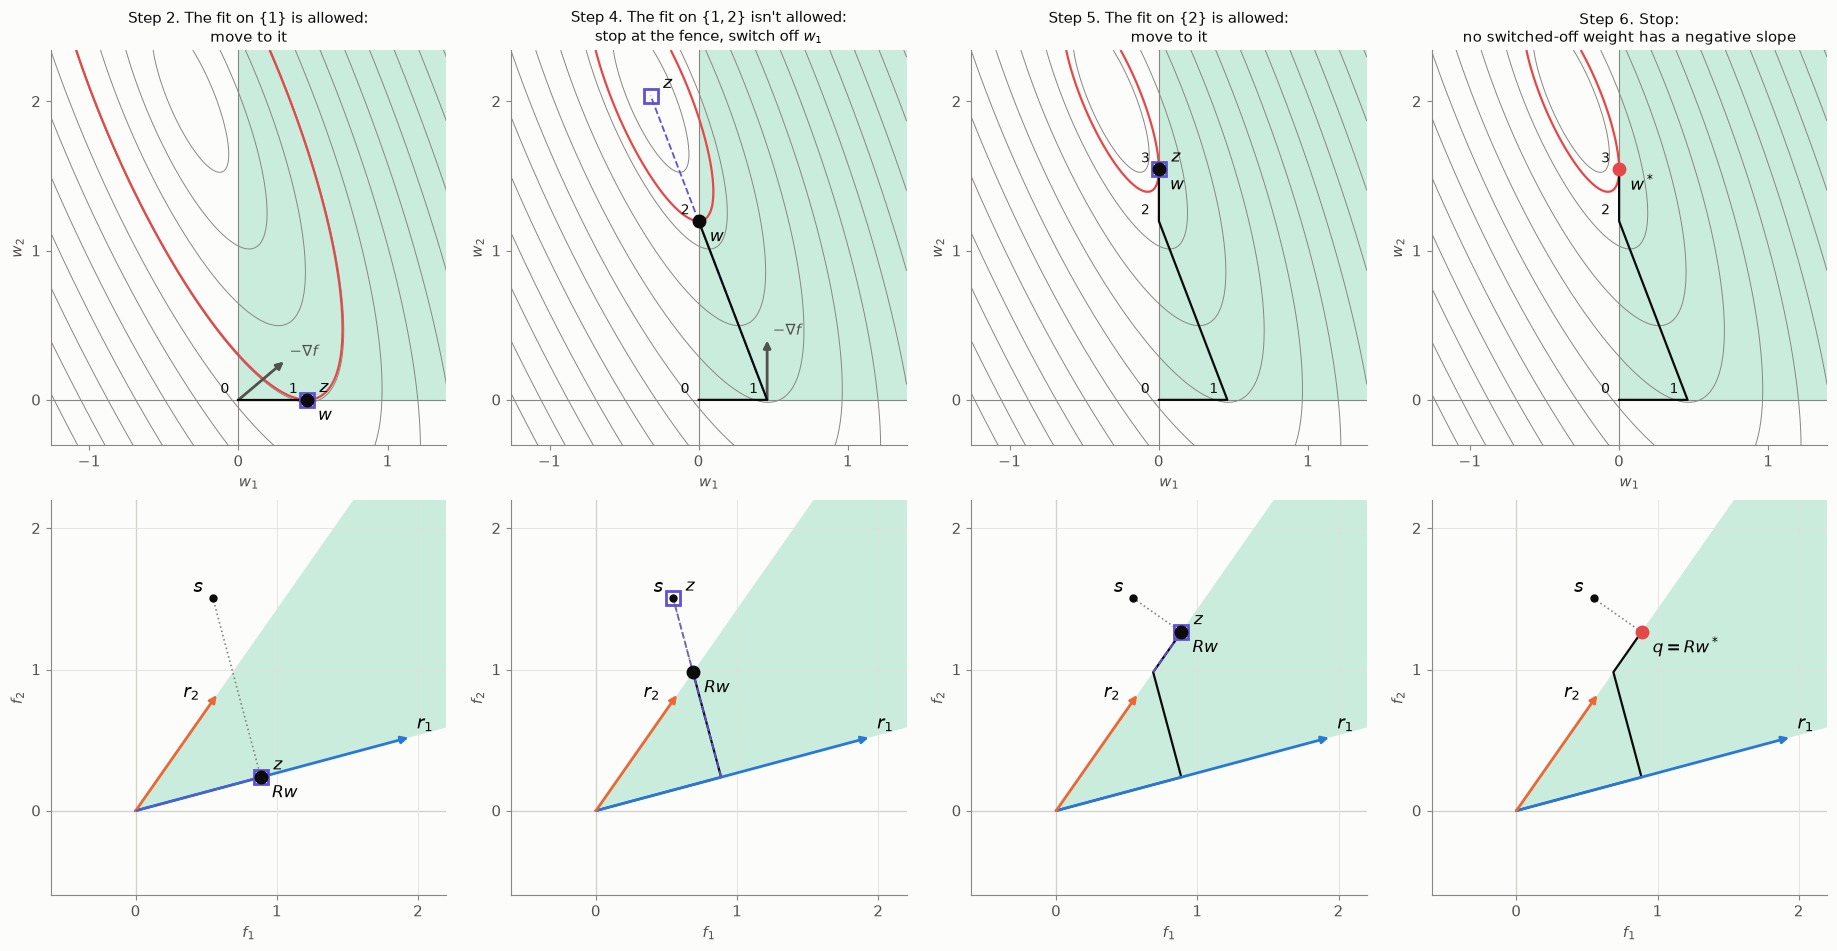

In [2]:
A.walk_static()

**Figure 3.1.** The steps of the walk that move $w$, in weight space (top) and spectrum space
(bottom). The black path is the walk so far, with the points it has visited numbered in
order, and the black dot is where it is now. The violet square $z$ is the least-squares fit
that the step aimed at, with its line of aim dashed. In weight space, the red contour is the
one through the current point, so you can watch the error drop. The gray arrow is the
downhill direction $-\nabla f$ at the point where the step began.

Following along with the numbers:

- **Steps 1–2.** At $w = 0$ the slopes are $\lambda = -2c = (-3.67, -3.09)$. Both are
  negative, and $\lambda_1$ is more negative, so $w_1$ is switched on. The fit on $\{1\}$ is
  $w_1 = 0.46$, which is allowed, so the walk moves there, along the $w_1$ axis. In spectrum
  space, $Rw$ moves out along $r_1$ to the point closest to $s$. The error drops from $2.56$
  to $1.72$.
- **Steps 3–4.** Now $\lambda = (0, -1.68)$: $w_1$ is at the bottom in its own direction, and
  the ground slopes down as $w_2$ increases, so $w_2$ is switched on. The fit on $\{1, 2\}$ is
  the bottom of the bowl, $\hat w = (-0.32, 2.04)$. It isn't allowed. So the walk heads
  straight for it, and stops where that line crosses the fence $w_1 = 0$, at
  $w = (0, 1.20)$, 59% of the way there. Then $w_1$ is switched off. In spectrum space, $Rw$
  heads straight for $s$ (two columns fit $s$ exactly, so the full fit is $s$ itself) and
  stops at the edge of the cone. The error drops to $0.29$.
- **Step 5.** The fit on $\{2\}$ is $w_2 = 1.55$, allowed. The walk slides up the $w_2$ axis
  to it, and the error drops to $0.17$.
- **Step 6.** The slopes are $\lambda = (1.07, 0)$. The only switched-off weight, $w_1$, has
  a positive slope, so the walk stops. That's the answer.

The widget below steps through the walk one step at a time, including the steps that only
switch a weight on. Move $s$ or change the length of $r_1$ to see other walks. Most are
shorter: when the longer column also points closer to $s$, the walk never has to back off.

In [3]:
A.walk_widget()

interactive(children=(IntSlider(value=0, continuous_update=False, description='step', max=8, style=SliderStyle…

Two things to notice in the pictures.

- **The walk runs along the fence.** Apart from the start, it's always on an edge of the
  quadrant, or inside it, and every move goes downhill. In spectrum space, $Rw$ never leaves
  the cone.
- **Backing off is a compromise.** The fit $z$ said "go here", the fence said "not past
  here", and the walk went as far as it was allowed in $z$'s direction. That's not the best
  point on the new support, which is why the walk fits again right after.

## 3. Why it works

Three facts make the walk work. First, switching on a weight whose slope is negative always
pays off. As in notebook 2, "the fit on $P$" means the least-squares fit using only the columns
in $P$, with the other weights at zero.

> **Theorem 13 (switching on a downhill weight).** Suppose the columns in $P$ are linearly
> independent, $w$ is the fit on $P$, and $\lambda_t < 0$ for some $t$ not in $P$. Then
> 1. the columns in $P$ together with $r_t$ are still linearly independent, and
> 2. the fit $z$ on $P \cup \{t\}$ has $z_t > 0$ and a smaller error, $f(z) < f(w)$.

*Proof.* (1) Since $w$ is the fit on $P$, its slopes there are zero: $\lambda_P = 0$. If $r_t$
were a combination $R_P a$ of the columns in $P$, then
$\lambda_t = -2\,r_t \cdot e = -2\,a \cdot (R_P^\top e) = a \cdot \lambda_P = 0$, which isn't
negative.

(2) Because $\lambda_t < 0$, a small step from $w$ in direction $w_t$ goes downhill
(Theorem 7): there's a point $y$, equal to $w$ except that $y_t > 0$, with $f(y) < f(w)$. The fit
$z$ is the lowest point among all weights that are zero outside $P \cup \{t\}$, and $y$ is one
of those, so $f(z) \le f(y) < f(w)$.

Now suppose $z_t \le 0$. Walk along the segment from $y$ to $z$. The $t$-th weight goes
from $y_t > 0$ to $z_t \le 0$, so somewhere on the segment, possibly at $z$ itself, there's a
point $x$ with $x_t = 0$. Along a line, $f$ is a parabola that opens upward (Theorem 7 again),
and such a parabola is never above the larger of its two end values on an interval. So
$f(x) \le \max(f(y), f(z)) = f(y) < f(w)$. But $x$ is zero outside $P$, and $w$ is the best
such point. That's a contradiction, so $z_t > 0$. $\blacksquare$

Part 1 is a bonus: the walk never needs to check for dependent columns, the way enumeration
did in Theorem 11. Every system $G_{PP}\,z = c_P$ it meets has a unique solution.

Second, backing off at the fence keeps the walk allowed, and never goes uphill.

> **Theorem 14 (backing off).** Suppose $w \ge 0$ is zero outside $P$, $z$ is the fit on $P$,
> and some weight of $z$ in $P$ is $\le 0$. For each such weight with $w_i > 0$, let
> $$\alpha_i = \frac{w_i}{w_i - z_i},$$
> and let $\alpha$ be the smallest of them. Then $0 < \alpha \le 1$, the point
> $x = w + \alpha(z - w)$ is allowed, its $i$-th weight is zero for the $i$ that gave the
> smallest $\alpha_i$, and
> $$f(x) \le (1 - \alpha) f(w) + \alpha f(z) \le f(w).$$

*Proof.* The $i$-th weight of $x$ is $(1 - \alpha) w_i + \alpha z_i$. For a weight with
$z_i \le 0 < w_i$, it falls steadily as $\alpha$ grows, and reaches zero exactly at
$\alpha_i$, which is in $(0, 1]$. Taking the smallest $\alpha_i$ keeps every such weight
$\ge 0$, and zeroes the one that gave it. Weights with $z_i > 0$ are averages of two
non-negative numbers, so they stay $\ge 0$. For the error, the first inequality says a
parabola that opens upward lies below its chords. The second holds because $w$ is zero outside
$P$ and $z$ is the best such point, so $f(z) \le f(w)$. $\blacksquare$

The theorem asks for $w_i > 0$ in the formula. That's always true for the weights that
matter: the walk only ever holds positive weights in $P$, apart from the one just switched on,
and that one has $z_t > 0$ by Theorem 13, so it never sets the limit on the first back-off.

Third, these two facts together rule out going round in circles.

> **Theorem 15 (the walk ends at the answer).** The active-set method stops after finitely many
> steps, at an NNLS solution.

*Proof.* Look at the walk each time it reaches step 1. There, $w$ is the fit on $P$, the
columns in $P$ are independent (Theorem 13 adds only independent columns, and switching
columns off keeps them independent), and the weights in $P$ are positive.

Between one visit to step 1 and the next, the error strictly drops. Theorem 13 says the first
fit $z$ after switching on $w_t$ has $f(z) < f(w)$. If $z$ is accepted, that's the drop. If
not, the first back-off goes to a point with error at most
$(1 - \alpha) f(w) + \alpha f(z)$, which is less than $f(w)$ because $\alpha > 0$. Every later
back-off or fit in the same round goes no higher (Theorem 14, and a fit on $P$ is at least as
good as any point that's zero outside $P$).

So the errors at successive visits to step 1 strictly decrease. But the point $w$ at a visit
is the fit on $P$, which depends only on $P$, so the same $P$ can never come back: its error
would be the same. There are finitely many supports, so there are finitely many visits.
Within a visit, each back-off switches off at least one weight, so there are at most $|P|$
of them. So the walk stops.

When it stops, every switched-off weight has $\lambda_i \ge 0$ (that's the stopping rule),
every switched-on weight has $\lambda_i = 0$ ($w$ is the fit on $P$), and $w \ge 0$. Those are
the KKT conditions, so $w$ is a solution (Theorem 9). $\blacksquare$

Notice how weak the bound in the proof is: one round per support, $2^m$ rounds at most,
no better than enumeration. The proof only shows the walk can't loop. In practice, the walk
is short, usually about one round for each weight in the answer, as you'll see on real
spectra below. There's no simple formula for how long it takes, though, and that matters
in notebook 5.

## 4. The code

Here's the whole method. Like notebook 2's enumeration, it works from $G$, $c$ and
$s^\top s$ alone, so after they're computed it never touches a long vector again:

In [4]:
def nnls_by_active_set(R, s, tol=1e-10):
    """NNLS by Lawson and Hanson's active-set method (Theorems 13, 14 and 15)."""
    G, c, ss = normal_equations(R, s)
    m = len(c)
    w, P = np.zeros(m), []  # start with every weight switched off
    while True:
        lam = 2 * (G @ w - c)  # the slopes, from Theorem 7
        off = [i for i in range(m) if i not in P]
        if not off or lam[off].min() >= -tol:
            return w  # no switched-off weight slopes downhill: KKT holds (Theorem 9)
        P.append(min(off, key=lambda i: lam[i]))  # switch on the steepest (Theorem 13)
        while True:
            z = np.zeros(m)
            z[P] = support_fit(G, c, ss, P)[0]  # the fit on P: solves G_PP z = c_P
            if np.all(z[P] > 0):
                w = z  # allowed: move to it
                break
            # not allowed: back off at the fence (Theorem 14)
            alpha = min(w[i] / (w[i] - z[i]) for i in P if z[i] <= 0)
            w = w + alpha * (z - w)
            P = [i for i in P if w[i] > tol]  # switch off the weights that reached zero
            w[[i for i in range(m) if i not in P]] = 0

The `tol` is there because of rounding. A slope or weight that is zero in exact arithmetic
comes out as something like $10^{-16}$ in floating point, and without a tolerance, a slope of
$-10^{-16}$ would switch on a weight for no reason. (The package version, `active_set_steps`,
picks its tolerance from the size of $G$ and $c$ instead of a fixed number.) Let's check it on
the walk above, on all ten real references, and on a thousand random problems, against SciPy
and against enumeration:

In [5]:
R_walk, s_walk = A.walk_problem(**A.WALK_EXAMPLE)
print("the walk above:", nnls_by_active_set(R_walk, s_walk))

w_ours = nnls_by_active_set(spectra.R, spectra.s)
w_scipy, _ = scipy.optimize.nnls(spectra.R, spectra.s)
print("ten references, largest difference from SciPy:", f"{np.abs(w_ours - w_scipy).max():.1e}")

rng = np.random.default_rng(0)
worst_scipy = worst_enumeration = 0.0
for _ in range(1000):
    m = int(rng.integers(1, 7))
    R_test = rng.random((30, m))
    s_test = R_test @ rng.normal(size=m) + 0.05 * rng.normal(size=30)
    w_test = nnls_by_active_set(R_test, s_test)
    worst_scipy = max(worst_scipy, np.abs(w_test - scipy.optimize.nnls(R_test, s_test)[0]).max())
    worst_enumeration = max(
        worst_enumeration, np.abs(w_test - nnls_enumerate(R_test, s_test)).max()
    )
print(f"1000 random problems, largest difference from SciPy {worst_scipy:.1e}")
print(f"                      largest difference from enumeration {worst_enumeration:.1e}")

the walk above: [0.     1.5455]
ten references, largest difference from SciPy: 4.9e-13


1000 random problems, largest difference from SciPy 1.1e-14
                      largest difference from enumeration 1.3e-14


The random problems agree to about 14 digits. The ten-reference fit agrees to about 12. That
fit includes two references that are nearly identical, As$_2$O$_3$ and sodium arsenite, and
nearly identical references cost accuracy. That's a first taste of notebook 4.

One difference from Lawson and Hanson's own version is worth knowing about. They don't form
$G = R^\top R$ at all. They work with $R$ itself, through a QR factorization, which is updated
a column at a time as weights are switched on and off. That's more accurate when the
references are nearly alike, for reasons notebook 4 explains. Working from $G$ and $c$, as here,
is the shortcut that the "fast NNLS" variant of Rasmus Bro and Sijmen de Jong (1997) takes,
and it's the same shortcut notebook 2 took for enumeration.

## 5. The walk on real spectra

Now the real thing: the measured arsenic spectrum, fit with all ten bundled references at
once. Here's every step of the walk:

In [6]:
steps = active_set_steps(spectra.R, spectra.s)
labels = spectra.labels
pd.DataFrame(
    [
        {
            "step": step.kind,
            "weight switched on or off": ", ".join(labels[i] for i in step.changed),
            "references on": len(step.support),
            "error f(w)": step.error,
        }
        for step in steps
    ]
).round(4)

,step,weight switched on or off,references on,error f(w)
0,start,,0,181.1079
1,add,scorodite,1,181.1079
2,fit,,1,38.0288
3,add,orpiment,2,38.0288
4,fit,,2,1.6598
5,add,arsenopyrite,3,1.6598
6,fit,,3,0.1736
7,add,arsenate on diopside,4,0.1736
8,backtrack,scorodite,3,0.1489
9,fit,,3,0.1489


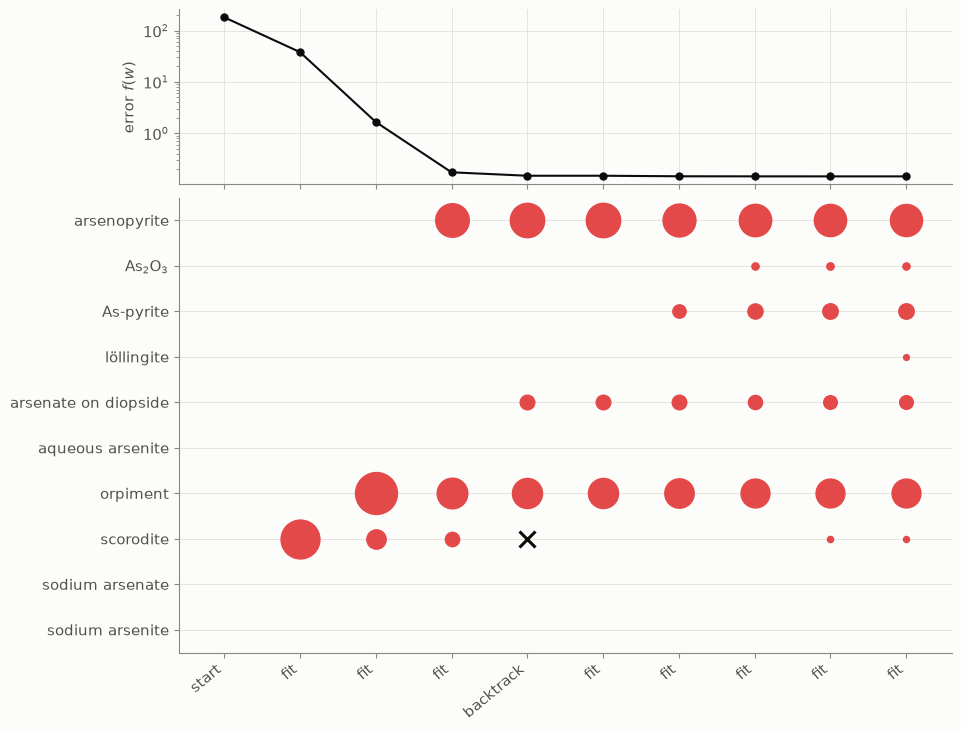

In [7]:
P.show(A.support_chart_figure(spectra))

**Figure 3.2.** The walk through all ten references. Bottom: the weights after each move,
one column per move, with a dot's area showing its weight; the cross marks the weight switched
off by the back-off. Top: the error after each move, on a log scale.

The walk switches on scorodite first: it's the reference with the largest dot product with
$s$ (Exercise 4). Then orpiment and arsenopyrite, and by then the error has dropped from 181 to
0.17, a factor of a thousand. Then something interesting happens. Switching on arsenate on
diopside makes the fit want a *negative* amount of scorodite, so the walk backs off and
switches scorodite off. Three rounds later, with other references on, scorodite's slope is
negative again and it's switched back on, with a much smaller weight. That's allowed: a
weight can come back, but the *support* can't repeat (Theorem 15), and it doesn't.

The answer switches on 7 of the 10 references, and the walk solved 9 linear systems to get
there, 8 fits and 1 back-off. The
last few rounds barely change the error, from 0.1453 to 0.1447: they add references with
tiny weights, like 0.005 of löllingite. Whether they *should* be in the fit is a statistics
question, not an NNLS one, and it's what MrFitty's cross-validation is for. NNLS just finds
the best fit using the references it's given.

Here's the answer, checked against enumeration over all $2^{10} - 1 = 1023$ supports:

In [8]:
w_star = steps[-1].w
print("active set: ", w_star)
print("enumeration:", nnls_enumerate(spectra.R, spectra.s))
print("KKT slopes: ", gradient(spectra.R, spectra.s, w_star).round(4) + 0.0)

active set:  [0.4524 0.013  0.0971 0.0047 0.0735 0.     0.3636 0.0062 0.     0.    ]
enumeration: [0.4524 0.013  0.0971 0.0047 0.0735 0.     0.3636 0.0062 0.     0.    ]
KKT slopes:  [0.     0.     0.     0.     0.     0.055  0.     0.     0.0216 0.0028]


The slopes are zero for the seven references that are on, and positive for the three that
are off: aqueous arsenite, sodium arsenate and sodium arsenite.

## 6. Enumeration or active set?

Both methods solve small systems $G_{PP}\,z = c_P$. Enumeration solves one for every support,
$2^m - 1$ of them. The active-set method solves one per fit or back-off, and the walk is
short. To compare them, here are both methods on random subsets of the ten references, for
every size $m$ from 1 to 10:

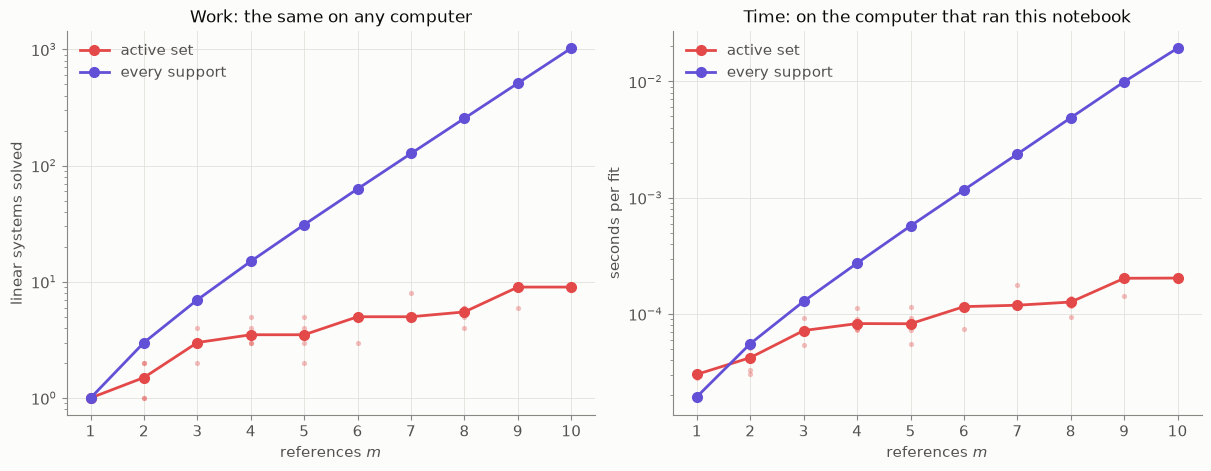

In [9]:
costs = A.measure_costs(spectra)
P.show(A.cost_figure(costs))

**Figure 3.3.** The work (left) and time (right) to fit the measured spectrum with $m$ of the
bundled references, for a few random choices of references at each $m$. The faint dots are
individual fits and the lines join the medians. Left: the number of linear systems each
method solves. Enumeration's count is always $2^m - 1$; the active-set method's depends on
the walk. Right: seconds per fit, using this package's plain-Python solvers.

The left panel is the important one, because it doesn't depend on the computer. Enumeration
doubles with each reference. The active-set walk grows roughly in step with $m$: about as
many fits as references in the answer, plus a few back-offs. At three references, the two are
close, 7 systems against about 3. At ten, it's 1023 against about 9.

The timings on the right follow the same shape. Here enumeration is at a further
disadvantage, because it checks every support for dependent columns, and the active-set
method doesn't need to (Theorem 13). Your numbers will differ from the ones in the
rendered notebook, but the shape won't.

So why does MrFitty's cross-validation notebook use enumeration? Three reasons, and they're
the subject of the rest of the series:

- **Its fits are tiny.** MrFitty scores every combination of up to three references from
  its pool, 2,324 combinations for this sample, each refit on a thousand different holdouts.
  At $m \le 3$ there are at most 7 supports, and the walk's advantage hasn't kicked in yet.
- **Enumeration does the same work every time.** It has no decisions in it: every fit tries
  the same supports in the same order. That makes it easy to do *millions* of fits at once,
  as one big array computation, which is what notebook 5 does. The active-set walk is
  different for every fit, with a different number of steps, so it's much harder to batch.
- **The systems share a structure.** Every support's $G_{PP}$ is a corner of the same
  matrix $G$. Notebook 4 shows how to solve them accurately, and how to tell when the answer
  can't be trusted, using one check per fit that covers every support at once.

## Exercises

**1.** *The first step.* Show that the walk's first move switches on the reference $r_t$ with
the largest $c_t = r_t \cdot s$, provided that's positive, and moves to $w_t = c_t / G_{tt}$.
What does the walk do if every $c_i \le 0$? (Compare notebook 2, Exercise 2.)

<details><summary>Solution</summary>

At $w = 0$ the slopes are $\lambda = 2(G \cdot 0 - c) = -2c$, so the most negative slope belongs
to the largest $c_t$, and it's negative exactly when $c_t > 0$. The fit on $\{t\}$ solves the
$1 \times 1$ system $G_{tt}\, z_t = c_t$, so $z_t = c_t / G_{tt} > 0$, which is allowed (as
Theorem 13 promised). If every $c_i \le 0$, every slope at $w = 0$ is $\ge 0$, so the walk stops
immediately at $w = 0$, which is the answer by notebook 2's Exercise 2.
</details>

**2.** *Orthogonal references.* Suppose the columns of $R$ are mutually orthogonal, so $G$ is
diagonal. Show that the walk never backs off, and that its answer is
$w^*_i = \max(0, \hat w_i)$: fit without the constraint, then round negative weights up to
zero. (Notebook 2, Exercise 1 showed that this shortcut fails in general.) How many fits does
the walk do?

<details><summary>Solution</summary>

With $G$ diagonal, the system $G_{PP}\,z = c_P$ splits into separate equations
$G_{ii} z_i = c_i$, so the fit on any $P$ has $z_i = c_i / G_{ii} = \hat w_i$ for $i$ in $P$,
whatever else is in $P$. And the slopes $\lambda_i = 2(G_{ii} w_i - c_i)$ each depend only on
their own weight. A switched-off weight has $\lambda_i = -2c_i$, so the walk switches on
exactly the weights with $c_i > 0$, the most positive first. Each fit gives those weights
$\hat w_i > 0$ and leaves the others alone, so no fit is ever disallowed and there's no
back-off. It stops when every remaining $c_i \le 0$, that is, $\hat w_i \le 0$. So
$w^*_i = \hat w_i$ when $\hat w_i > 0$ and $0$ otherwise, after one fit per positive $\hat w_i$.
Real spectra are far from orthogonal (notebook 2 found $G$'s eigenvalues ranging from 0.45 to
490), which is why the walk has to work harder.
</details>

**3.** *Break it.* Here's a tempting simplification. Fit with every weight switched on.
Switch off *every* weight that came out negative, and fit again. Repeat until no weight is
negative. It never switches a weight back on. Run it on the problem below, compare it with
the active-set method, and find the KKT condition its answer fails.

In [10]:
def drop_negatives(R, s):
    """Fit, switch off every negative weight, and refit, until no weight is negative."""
    P = list(range(R.shape[1]))
    while P:
        w = np.zeros(R.shape[1])
        w[P] = lstsq(R[:, P], s)
        if np.all(w[P] >= 0):
            return w
        P = [i for i in P if w[i] >= 0]
    return np.zeros(R.shape[1])


rng = np.random.default_rng(25)
R3 = rng.random((3, 3))
s3 = R3 @ rng.normal(size=3)

<details><summary>Solution</summary>

The full fit is $\hat w \approx (1.944, -0.228, -0.155)$. `drop_negatives` switches off both
$w_2$ and $w_3$ at once, refits with $w_1$ alone, gets $w = (1.757, 0, 0)$, and stops. The
active-set method finds $w^* \approx (1.739, 0, 0.091)$, with a smaller error, $0.00121$
against $0.00166$. At `drop_negatives`'s answer, the slopes are about
$\lambda = (0, 0.021, -0.010)$: $w_3$ is switched off but its slope is negative, so the KKT
condition $\lambda_3 \ge 0$ fails, and switching $w_3$ back on would lower the error.

What went wrong: $w_3$ was negative only because $w_2$ was on. Once $w_2$ was off, $w_3$ wanted
to be positive, but the method had no way to let it back in. The active-set method checks the
slopes of the switched-off weights at every round, which is exactly what lets weights back
in. Check it yourself:

```python
for w in [drop_negatives(R3, s3), nnls_by_active_set(R3, s3)]:
    print(w, objective(R3, s3, w), gradient(R3, s3, w))
```
</details>

**4.** *Predict the walk.* Before looking back at Figure 3.2, use Exercise 1 to predict which
reference the walk on real spectra switches on first, and its first weight. Check your
prediction with $G$ and $c$ from `normal_equations(spectra.R, spectra.s)`.

<details><summary>Solution</summary>

The largest entry of $c = R^\top s$ belongs to scorodite, and $c_t / G_{tt}$ gives its first
weight:

```python
G, c, ss = normal_equations(spectra.R, spectra.s)
t = np.argmax(c)
print(spectra.labels[t], c[t] / G[t, t])
```

Scorodite lines up best with the measured spectrum by the dot product, yet it ends the walk
with a weight of only 0.006. The reference that looks best on its own and the references
that matter in the best mixture can be quite different things.
</details>

## Summary

- The **active-set method** of Lawson and Hanson walks from support to support: switch on the
  switched-off weight with the most negative slope, fit on the switched-on weights, and back
  off at the fence when the fit isn't allowed. It stops when the KKT conditions hold.
- **Switching on a downhill weight** always gives a fit with that weight positive and a
  smaller error, and keeps the columns independent (Theorem 13).
- **Backing off** keeps the walk allowed and never goes uphill (Theorem 14).
- So the error strictly drops from round to round, no support repeats, and the walk **ends
  at the answer** (Theorem 15).
- On real spectra, the walk is short: 9 linear systems for ten references, against 1023
  for enumeration. Weights can be switched off and back on along the way.
- Enumeration still has a place: for **tiny fits, done by the million**, its fixed, decision-free
  work is easier to make fast. That's where the series goes next.

**Next:** [notebook 4](04_numerics_cholesky_conditioning.ipynb) looks closely at the small systems $G_{PP}\,z = c_P$ that both
methods solve: how to solve them with the Cholesky factorization, and how much accuracy is
lost when references are nearly alike.